# 08. 評価指標（PSNR/SSIM → LPIPS/CLIP-IQA）とハルシネーション対策（残差射影・不確実性マップ）

**セミナー対応章**：第4章（1）（3）　｜　**推奨ランタイム**：Colab無料枠 T4 GPU　｜　**所要時間**：約5分

1. 同じ劣化画像を「補間 / GAN / 拡散モデル」で超解像し、**PSNR・SSIM・LPIPS・CLIP-IQA** で評価 → 指標によって勝者が変わる（知覚–歪みトレードオフ）
2. **残差射影（Residual Projection / Back-projection）**：出力を縮小したら入力と一致する、という制約で生成結果を補正
3. **不確実性マップ**：seed を変えて複数回生成し、結果がばらつく場所＝「AIが想像で描いた場所」を可視化

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


In [2]:
if IN_COLAB:
    pip_install("torchmetrics", "piq")
import cv2
import lpips
from PIL import ImageFilter
import spandrel
from torchmetrics.multimodal import CLIPImageQualityAssessment
from diffusers import StableDiffusionUpscalePipeline

W1031 11:03:31.153000 44960 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 1. 3種類の超解像結果を作る（128 → 512）

In [3]:
hr = load_portrait()                          # 顔が大きく写った高画質画像（512x512）
lr = hr.resize((128, 128), Image.BICUBIC)     # 1/4 に縮小したものを入力にする

esrgan = spandrel.ModelLoader().load_from_file(
    download("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth")).to(DEVICE).eval()
sd_up = StableDiffusionUpscalePipeline.from_pretrained("stabilityai/stable-diffusion-x4-upscaler", torch_dtype=DTYPE).to(DEVICE)
sd_up.set_progress_bar_config(disable=True)

def sd_sr(img, seed=0):
    return sd_up(prompt="a photo of a woman wearing a red hat, high quality, detailed", image=img, num_inference_steps=30,
                 noise_level=20, generator=torch.Generator(DEVICE).manual_seed(seed)).images[0]

with torch.no_grad():
    outs = {
        "Bicubic": lr.resize(hr.size, Image.BICUBIC),
        "Blurred GT": hr.filter(ImageFilter.GaussianBlur(2)),
        "Real-ESRGAN": tensor_to_pil(esrgan(to_tensor(lr).to(DEVICE))),
        "SD x4 Upscaler": sd_sr(lr),
    }

D:\seminar_env\venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

D:\seminar_env\venv\Lib\site-packages\diffusers\pipelines\stable_diffusion\pipeline_stable_diffusion_upscale.py:528: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


## 2. 4つの指標で評価
- **PSNR / SSIM**：正解との画素・構造の一致度（大きいほど良い）
- **LPIPS**：深層特徴空間での距離。人間の知覚的な差に近い（**小さいほど良い**）
- **CLIP-IQA**：正解画像なしで「Good photo / Bad photo」とのCLIP類似度から画質を推定（大きいほど良い）

D:\seminar_env\venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\seminar_env\venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


method             PSNR↑   SSIM↑  LPIPS↓ CLIP-IQA↑
Bicubic            28.92   0.788   0.388     0.606
Blurred GT         28.85   0.783   0.413     0.567
Real-ESRGAN        27.91   0.762   0.260     0.603
SD x4 Upscaler     25.69   0.597   0.312     0.971
Ground truth           -       -       -     0.941


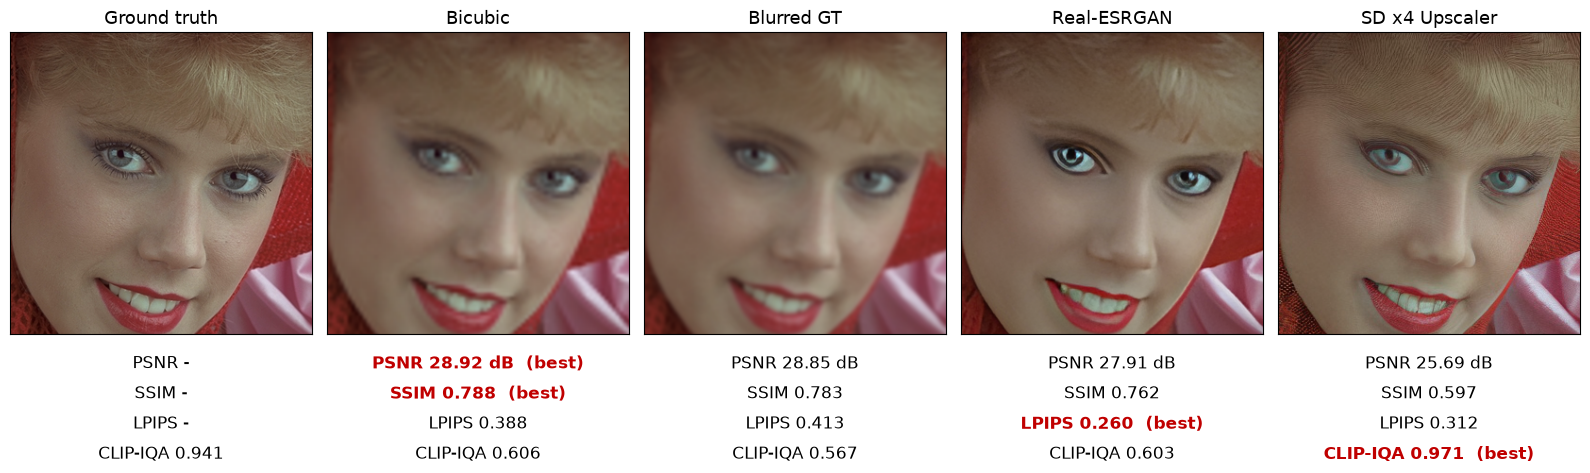

In [4]:
lp = lpips.LPIPS(net="alex", verbose=False).to(DEVICE)
clipiqa = CLIPImageQualityAssessment(prompts=("quality",)).to(DEVICE)

def lpips_score(a, b):
    with torch.no_grad():
        return lp(to_tensor(a).to(DEVICE) * 2 - 1, to_tensor(b).to(DEVICE) * 2 - 1).item()

def clipiqa_score(a):
    with torch.no_grad():
        return clipiqa(to_tensor(a).to(DEVICE)).item()

scores = {n: (psnr(im, hr), ssim(im, hr), lpips_score(im, hr), clipiqa_score(im)) for n, im in outs.items()}
print(f"{'method':16s} {'PSNR↑':>7s} {'SSIM↑':>7s} {'LPIPS↓':>7s} {'CLIP-IQA↑':>9s}")
for n, (p_, s_, l_, c_) in scores.items():
    print(f"{n:16s} {p_:7.2f} {s_:7.3f} {l_:7.3f} {c_:9.3f}")
gt_iqa = clipiqa_score(hr)
print(f"{'Ground truth':16s} {'-':>7s} {'-':>7s} {'-':>7s} {gt_iqa:9.3f}")

# 画像の下に各指標を表示（各指標で最も良い手法に (best)）
box = (110, 40, 430, 360)                     # 顔の部分を拡大して表示
best = {0: max, 1: max, 2: min, 3: max}
best_val = {k: f(v[k] for v in scores.values()) for k, f in best.items()}
fig, axes = plt.subplots(1, len(outs) + 1, figsize=(3.2 * (len(outs) + 1), 4.6))
for ax, (n, im) in zip(axes, [("Ground truth", hr)] + list(outs.items())):
    ax.imshow(im.crop(box)); ax.set_title(n, fontsize=13); ax.set_xticks([]); ax.set_yticks([])
    if n == "Ground truth":
        lines = [("PSNR -", False), ("SSIM -", False), ("LPIPS -", False), (f"CLIP-IQA {gt_iqa:.3f}", False)]
    else:
        v = scores[n]
        lines = [(f"{a} {b}" + ("  (best)" if np.isclose(v[k], best_val[k]) else ""), np.isclose(v[k], best_val[k]))
                 for a, b, k in [("PSNR", f"{v[0]:.2f} dB", 0), ("SSIM", f"{v[1]:.3f}", 1), ("LPIPS", f"{v[2]:.3f}", 2), ("CLIP-IQA", f"{v[3]:.3f}", 3)]]
    for i, (t, is_best) in enumerate(lines):    # best は太字・赤
        ax.text(0.5, -0.07 - 0.1 * i, t, transform=ax.transAxes, ha="center", va="top", fontsize=12,
                color="#C00000" if is_best else "black", fontweight="bold" if is_best else "normal")
plt.tight_layout(); plt.subplots_adjust(bottom=0.3); plt.show()

**観察ポイント（知覚–歪みトレードオフ, Blau & Michaeli 2018）**
- PSNR/SSIM は「ぼかした画像」を高く評価しがち（画素の平均二乗誤差は“平均的な答え”で最小になる）
- LPIPS・CLIP-IQA は生成系（GAN・拡散）を高く評価するが、**それが正しい細部かどうかは保証しない**
- FID（多数の画像の分布の近さ）は数百〜数万枚単位で使う指標で、1枚の画像の正しさは測れない
→ **用途に合わせて複数の指標＋下流タスク（OCR認識率・検査精度）＋専門家評価** を組み合わせる

## 3. 残差射影（Residual Projection）でハルシネーションを抑える
「超解像結果を縮小すると、観測された低解像度画像に一致するはず」という制約集合へ出力を射影します：
$$x \leftarrow x - \mathrm{Up}\big(\mathrm{Down}(x) - y_{LR}\big)$$
生成AIが描いた **観測と矛盾する成分だけ** を取り除き、観測と整合する細部は残します（ResShift・Resfusion なども同じ考え方を拡散過程に組み込んでいます）。

D:\seminar_env\venv\Lib\site-packages\diffusers\pipelines\stable_diffusion\pipeline_stable_diffusion_upscale.py:528: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


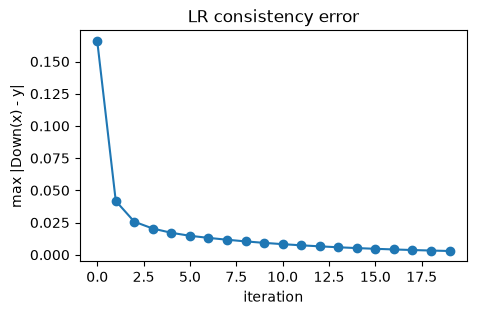

SD x4                PSNR 25.88  SSIM 0.605  LPIPS 0.306
SD x4 + projection   PSNR 26.88  SSIM 0.660  LPIPS 0.241


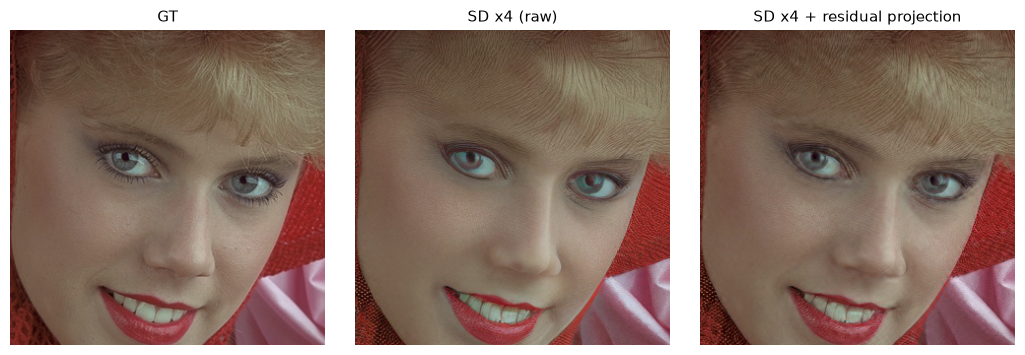

In [5]:
def residual_projection(sr, lr, iters=20):
    x = to_np(sr).astype(np.float32)
    y = to_np(lr).astype(np.float32)
    errs = []
    for _ in range(iters):
        d = cv2.resize(x, y.shape[1::-1], interpolation=cv2.INTER_AREA) - y        # 縮小して観測との差
        errs.append(np.abs(d).max())
        x = np.clip(x - cv2.resize(d, x.shape[1::-1], interpolation=cv2.INTER_CUBIC), 0, 1)
    return to_pil(x), errs

# 縮小方法を揃えるため、観測 LR を INTER_AREA で作り直して実験
lr_area = to_pil(cv2.resize(to_np(hr), (128, 128), interpolation=cv2.INTER_AREA))
sr0 = sd_sr(lr_area, seed=0)
sr_proj, errs = residual_projection(sr0, lr_area)
plt.figure(figsize=(5, 3)); plt.plot(errs, "o-"); plt.xlabel("iteration"); plt.ylabel("max |Down(x) - y|"); plt.title("LR consistency error"); plt.show()
for n, im in [("SD x4", sr0), ("SD x4 + projection", sr_proj)]:
    print(f"{n:20s} PSNR {psnr(im, hr):.2f}  SSIM {ssim(im, hr):.3f}  LPIPS {lpips_score(im, hr):.3f}")
show([hr.crop(box), sr0.crop(box), sr_proj.crop(box)], ["GT", "SD x4 (raw)", "SD x4 + residual projection"], size=3.5)

> **ノイズを含む入力の場合**：入力そのものに射影するとノイズまで戻ってしまいます。
> ハルシネーションの少ないノイズ除去（例：SwinIR・SCUNet）の結果を参照画像にして射影し、拡散モデルでの修復と交互に繰り返す方法が有効です（講師らの DIA2026 発表）。

## 4. 不確実性マップ：AIが「想像で描いた」場所を可視化する
生成AIの出力は確率的です。seed を変えて複数回生成し、画素ごとの **ばらつき（標準偏差）** を見ると、
観測から決まらない＝ハルシネーションが起きやすい場所が分かります。結果を提示するときは、このような **信頼度マップ** を添えるのが望ましいです。

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


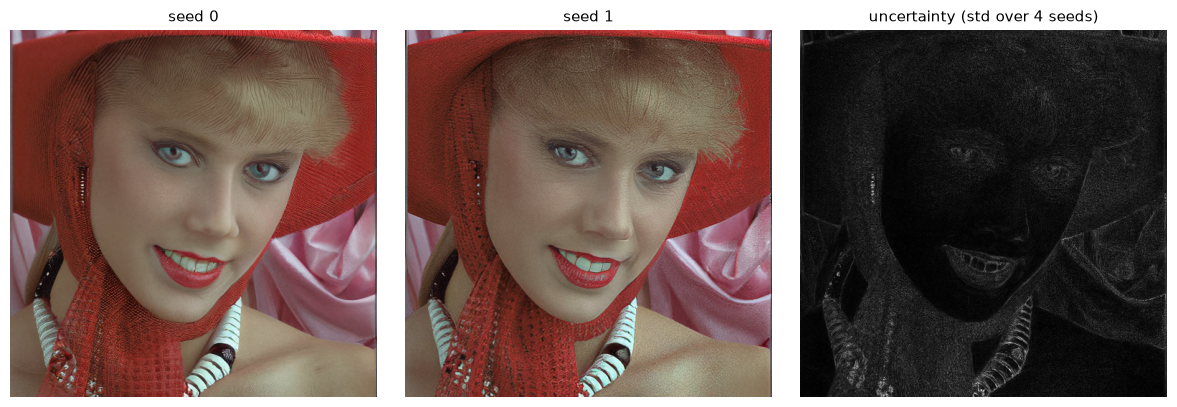

In [6]:
samples = [to_np(sd_sr(lr, seed=s)) for s in range(4)]
std_map = np.stack(samples).std(0).mean(-1)
show([to_pil(samples[0]), to_pil(samples[1]), std_map / std_map.max()],
     ["seed 0", "seed 1", "uncertainty (std over 4 seeds)"], size=4)

## まとめ
- 指標は1つで判断しない：**PSNR/SSIM（忠実性）× LPIPS/CLIP-IQA/FID（自然さ）× 下流タスク × 専門家評価**
- ハルシネーション対策：**残差射影で観測と整合させる**／**条件付けで縛る**（ノートブック06）／**不確実性を可視化して提示**
- 医療・検査・証拠用途では「原画像の保存・処理内容の記録・生成部分の明示」をセットで運用する